# Постороение графиков SHAP для моделей Catboost

In [1]:
# Устанавливаем нужную библитоеку при работе в colab
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 35.6 MB/s  0:00:02


In [2]:
# Импортируем библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

from tqdm import tqdm

In [3]:
# Подгружаем датасет
dataset = pd.read_excel('./objects_w_geo_prepared_V0_2j.xlsx')
dataset

,Unnamed: 0,space_m2,price_per_m2,total_price,office_class,floor,maxfloor,isCU,isNonCU,isEE,...,TotalOfficeCnt_2000,classACnt_500,classACnt_1000,classACnt_2000,isMoscowCity,isSkolkovo,inMKAD,AO,inGardenRing,distanceToCenter
0,0,10.0,380,3800,ND,1,6,0,1,0,...,486,11,27,124,0,0,1,ЦАО,0,3543.300243
1,1,5.0,800,4000,A,1,8,1,0,0,...,409,0,0,313,0,0,1,ВАО,0,8554.170939
2,2,2.6,2917,7566,A,0,0,0,0,0,...,2103,1,276,703,0,0,1,САО,0,5654.790987
3,3,5.0,1800,9000,B+,3,5,1,0,1,...,1,0,0,0,0,0,0,НЕОПР,0,15797.187090
4,5,5.0,1800,9000,B+,1,5,1,0,1,...,1,0,0,0,0,0,0,НЕОПР,0,15797.187090
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25097,33695,24605.0,10232,251754304,A,2,79,0,0,0,...,483,570,445,175,1,0,1,ЦАО,0,5479.273526
25098,33696,46566.3,6405,298257152,A,0,0,0,0,0,...,2241,92,56,654,0,0,1,САО,0,5366.792041
25099,33697,48297.0,6405,309342272,A,32,33,0,0,0,...,2241,92,56,654,0,0,1,САО,0,5366.792041
25100,33698,48298.0,6405,309348704,A,3,33,0,0,0,...,2241,92,56,654,0,0,1,САО,0,5366.792041


In [4]:
# Фильтры на нахождение внутри МКАДа и на подтягивание данных по административным округам
dataset = dataset.loc[dataset['inMKAD']==1].reset_index(drop=True)
dataset = dataset.loc[~(dataset['AO']=='НЕОПР')].reset_index(drop=True)

# Фильтры для классов офисов, для моделей отдельных классов
dataset = dataset.loc[dataset['office_class'].isin(['C'])].reset_index(drop=True)

dataset

,Unnamed: 0,space_m2,price_per_m2,total_price,office_class,floor,maxfloor,isCU,isNonCU,isEE,...,TotalOfficeCnt_2000,classACnt_500,classACnt_1000,classACnt_2000,isMoscowCity,isSkolkovo,inMKAD,AO,inGardenRing,distanceToCenter
0,28,7.0,1357,9500,C,1,1,0,0,0,...,557,0,35,6,0,0,1,CВАО,0,7592.842639
1,31,12.3,976,12000,C,3,4,0,1,0,...,708,0,1,77,0,0,1,ЮВАО,0,5449.520429
2,99,12.0,1167,14000,C,3,3,0,0,0,...,261,0,8,46,0,0,1,СЗАО,0,7381.297810
3,109,15.0,1100,16500,C,2,4,1,0,1,...,703,18,3,313,0,0,1,ВАО,0,6438.509305
4,110,10.0,1700,17000,C,0,0,1,0,1,...,1710,335,104,706,0,0,1,ЦАО,0,4255.609941
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,30901,1563.0,8642,13507446,C,2,2,0,1,0,...,1963,186,29,597,0,0,1,ЦАО,1,1374.498493
391,31285,1708.0,8896,15194368,C,3,0,0,1,0,...,1963,186,29,597,0,0,1,ЦАО,1,1374.498493
392,31355,1708.0,9150,15628200,C,4,0,0,1,0,...,1963,186,29,597,0,0,1,ЦАО,1,1374.498493
393,31553,1644.0,10477,17224872,C,4,4,0,0,0,...,632,11,28,213,0,0,1,ЦАО,0,3460.954391


### Строим катбуст

In [5]:
from catboost import CatBoostRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [6]:
# Список признаков
features = [
    # В1: Помещение + общая характеристика положения,
    'floor', 'maxfloor',
    'isCU', 'isNonCU', 'isEE', 'isOfficeCenter', 'isMall',
    'inTTK', 'inGardenRing', 'AO',
    'space_m2',
    # В2: В1 + метро
    'minDistSubway',
    # В3: В2 + окружение
    'cafe_500', 'cafe_1000', 'cafe_2000',
    'fast_food_500', 'fast_food_1000', 'fast_food_2000',
    'restaurant_500', 'restaurant_1000', 'restaurant_2000',
    'bank_500', 'bank_1000', 'bank_2000',
    'supermarket_500', 'supermarket_1000', 'supermarket_2000',
    'clothes_500', 'clothes_1000', 'clothes_2000',
    'cosmetics_500', 'cosmetics_1000', 'cosmetics_2000',
    'electronics_500', 'electronics_1000', 'electronics_2000',
    'mall_500', 'mall_1000', 'mall_2000',
    'histplaces_500', 'histplaces_1000', 'histplaces_2000',
    'distanceToCenter',
]
cat_features = ['isCU', 'isNonCU', 'isEE', 'inTTK', 'isOfficeCenter', 'isMall', 'AO']

In [7]:
### Train-test split с учетом повторения координат
dataset['coords_str'] = [str(round(dataset.at[i, 'avg_latitude'], 6)) + '_' + str(round(dataset.at[i, 'avg_longtitude'], 6)) for i in dataset.index]
# число уникальных точек
print('Уникальных адресов:', len(set(dataset['coords_str'])))

l1 = sorted(list(set(dataset['coords_str'])))

address_to_num = {val: i for i, val in enumerate(l1)}
dataset['address_index'] = [address_to_num[i] for i in dataset['coords_str']]
print(min(dataset.address_index), max(dataset.address_index))
dataset

Уникальных адресов: 229
0 228


,Unnamed: 0,space_m2,price_per_m2,total_price,office_class,floor,maxfloor,isCU,isNonCU,isEE,...,classACnt_500,classACnt_1000,classACnt_2000,isMoscowCity,isSkolkovo,inMKAD,AO,inGardenRing,distanceToCenter,address_index
0,28,7.0,1357,9500,C,1,1,0,0,0,...,0,35,6,0,0,1,CВАО,0,7592.842639,208
1,31,12.3,976,12000,C,3,4,0,1,0,...,0,1,77,0,0,1,ЮВАО,0,5449.520429,49
2,99,12.0,1167,14000,C,3,3,0,0,0,...,0,8,46,0,0,1,СЗАО,0,7381.297810,125
3,109,15.0,1100,16500,C,2,4,1,0,1,...,18,3,313,0,0,1,ВАО,0,6438.509305,148
4,110,10.0,1700,17000,C,0,0,1,0,1,...,335,104,706,0,0,1,ЦАО,0,4255.609941,161
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,30901,1563.0,8642,13507446,C,2,2,0,1,0,...,186,29,597,0,0,1,ЦАО,1,1374.498493,107
391,31285,1708.0,8896,15194368,C,3,0,0,1,0,...,186,29,597,0,0,1,ЦАО,1,1374.498493,107
392,31355,1708.0,9150,15628200,C,4,0,0,1,0,...,186,29,597,0,0,1,ЦАО,1,1374.498493,107
393,31553,1644.0,10477,17224872,C,4,4,0,0,0,...,11,28,213,0,0,1,ЦАО,0,3460.954391,117


In [8]:
# Создаем генератор.
# В данном случае берем один из сидов, ранее здействованных в обучении
rng = np.random.default_rng(seed=5000)

# берем 50 уникальных адресов для общей модели
test_index = rng.choice(max(dataset.address_index), size=50, replace=False)
test_index[0:5]

array([ 95,  56, 217,  43, 196])

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
  dataset[features], dataset['target'], test_size=0.2, random_state=5000
)
X_train = dataset.loc[~dataset['address_index'].isin(test_index)][features]
y_train = dataset.loc[~dataset['address_index'].isin(test_index)]['target']
X_test = dataset.loc[dataset['address_index'].isin(test_index)][features]
y_test = dataset.loc[dataset['address_index'].isin(test_index)]['target']
print(y_train.shape, y_test.shape)

(322,) (73,)


In [10]:
# Обучаем модель
model = CatBoostRegressor(
    iterations=400,
    learning_rate=0.015,
    random_state=5000,
    depth=10,
    loss_function='RMSE',
    cat_features = cat_features,
    verbose=100,
    l2_leaf_reg=2.0
)
model.fit(X_train, y_train)

0:	learn: 0.5395719	total: 54.4ms	remaining: 21.7s
100:	learn: 0.2656671	total: 2.24s	remaining: 6.62s
200:	learn: 0.1720332	total: 4.31s	remaining: 4.26s
300:	learn: 0.1334086	total: 6.38s	remaining: 2.1s
399:	learn: 0.1103304	total: 8.9s	remaining: 0us


CatBoostRegressor(cat_features=['isCU', 'isNonCU', 'isEE', 'inTTK', 'isOfficeCenter', 'isMall', 'AO'], depth=10, iterations=400, l2_leaf_reg=2.0, learning_rate=0.015, loss_function='RMSE', random_state=5000, verbose=100)

In [11]:
# Получаем предикты
predictions = model.predict(X_test)

In [12]:
# Смотрим технические метрики
mse = mean_squared_error(y_test, predictions)
print(f"\nMean Squared Error: {mse:.5f}; RMSE:{np.sqrt(mse):.5f}")
r2 = model.score(X_test, y_test)
print(f"CatBoost R2: {r2:.5f}")


Mean Squared Error: 0.10772; RMSE:0.32821
CatBoost R2: 0.50032


In [13]:
# Строим feature_importance (Catboost), в данном случае - топ-15
fi_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': model.get_feature_importance()
})

top_15_features = fi_df.sort_values(by='Importance', ascending=False).head(7)

display(top_15_features)

,Feature,Importance
11,minDistSubway,7.082082
10,space_m2,6.934574
9,AO,5.673129
12,cafe_500,5.053475
20,restaurant_2000,4.694207
25,supermarket_1000,4.526150
1,maxfloor,3.644347


# Строим SHAP значения и графики

In [14]:
# Строим SHAP-коэф-ты
explainer = shap.TreeExplainer(model, feature_perturbation="tree_path_dependent")
shap_values = explainer(X_test)

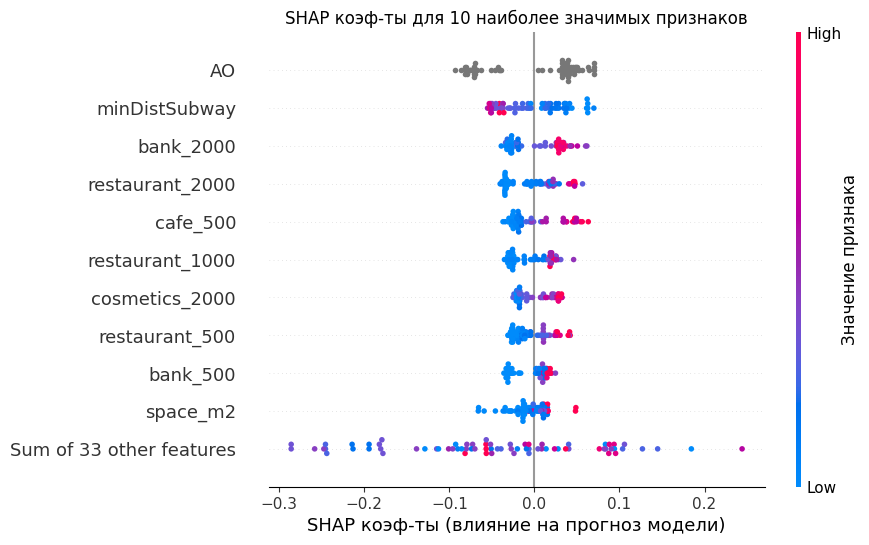

In [15]:
# Делаем графики для наболее значимых (в данном случае - 10) признаков
shap.plots.beeswarm(shap_values, max_display=11, show=False, color_bar_label='Значение признака')
plt.title('SHAP коэф-ты для 10 наиболее значимых признаков')
plt.xlabel('SHAP коэф-ты (влияние на прогноз модели)')
plt.show()

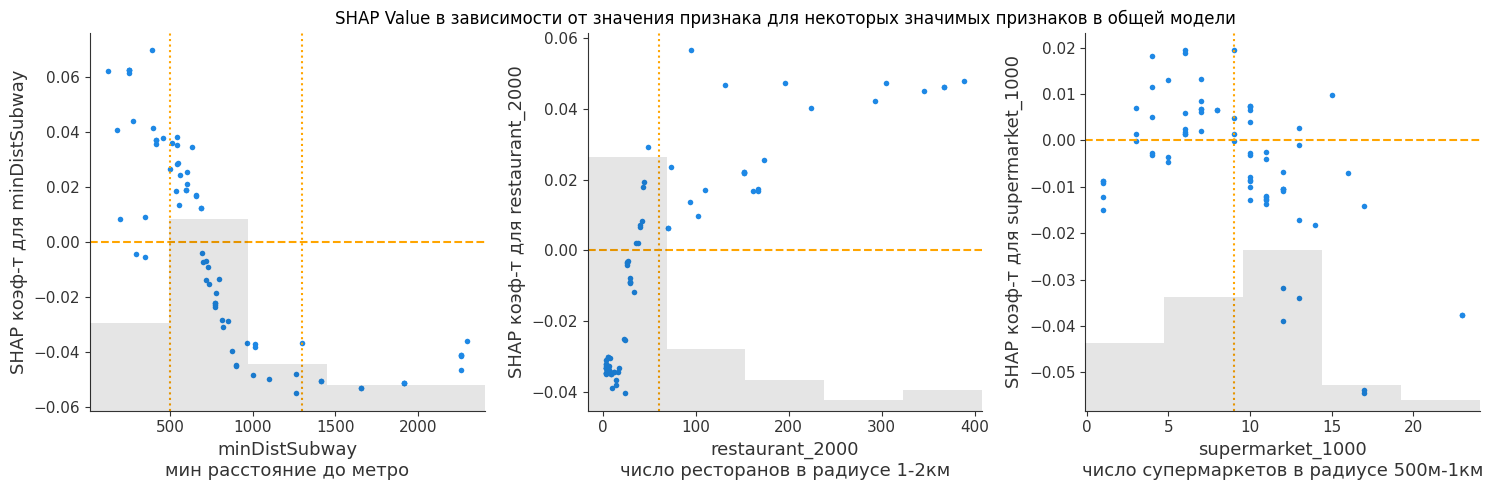

In [16]:
# Строим графики для отдельных признаков, ищем пороги
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
plt.sca(axs[0])
shap.plots.scatter(shap_values[:, "minDistSubway"], ax=axs[0], show=False)
axs[0].set_ylabel('SHAP коэф-т для minDistSubway')
axs[0].set_xlabel('minDistSubway\nмин расстояние до метро')
axs[0].axhline(y=0, color='orange', linestyle='--')
axs[0].axvline(x=500, color='orange', linestyle=':')
axs[0].axvline(x=1300, color='orange', linestyle=':')
plt.sca(axs[1])
plt.title('SHAP Value в зависимости от значения признака для некоторых значимых признаков в общей модели')
shap.plots.scatter(shap_values[:, "restaurant_2000"], ax=axs[1], show=False)
axs[1].set_ylabel('SHAP коэф-т для restaurant_2000')
axs[1].set_xlabel('restaurant_2000\nчисло ресторанов в радиусе 1-2км')
axs[1].axhline(y=0, color='orange', linestyle='--')
axs[1].axvline(x=60, color='orange', linestyle=':')
plt.sca(axs[2])
shap.plots.scatter(shap_values[:, "supermarket_1000"], ax=axs[2], show=False)
axs[2].set_ylabel('SHAP коэф-т для supermarket_1000')
axs[2].set_xlabel('supermarket_1000\nчисло супермаркетов в радиусе 500м-1км')
axs[2].axhline(y=0, color='orange', linestyle='--')
axs[2].axvline(x=9, color='orange', linestyle=':')

plt.tight_layout()
plt.show()

# Смотрим на средний модуль SHAP значений интересующих нас признаков
Оцениваем степень их влияния на прогоноз модели в целом

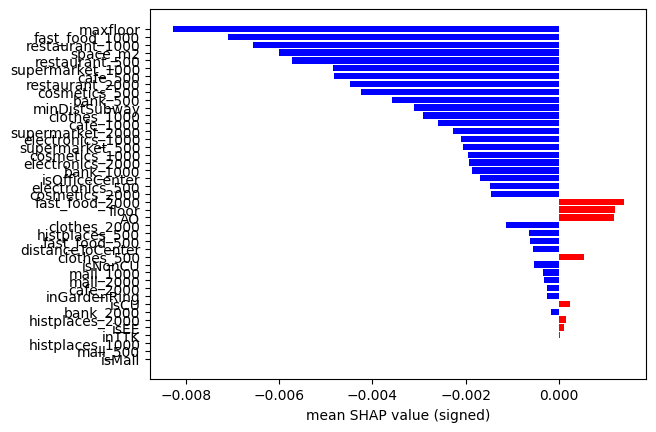

In [17]:
mean_shap = np.mean(shap_values.values, axis=0)
features = shap_values.feature_names

df = pd.DataFrame({"Feature": features, "Mean_SHAP": mean_shap})
df["Abs_SHAP"] = df["Mean_SHAP"].abs()
df = df.sort_values(by="Abs_SHAP", ascending=True)

plt.barh(df["Feature"], df["Mean_SHAP"], color=np.where(df["Mean_SHAP"] > 0, "red", "blue"))
plt.xlabel("mean SHAP value (signed)")
plt.show()

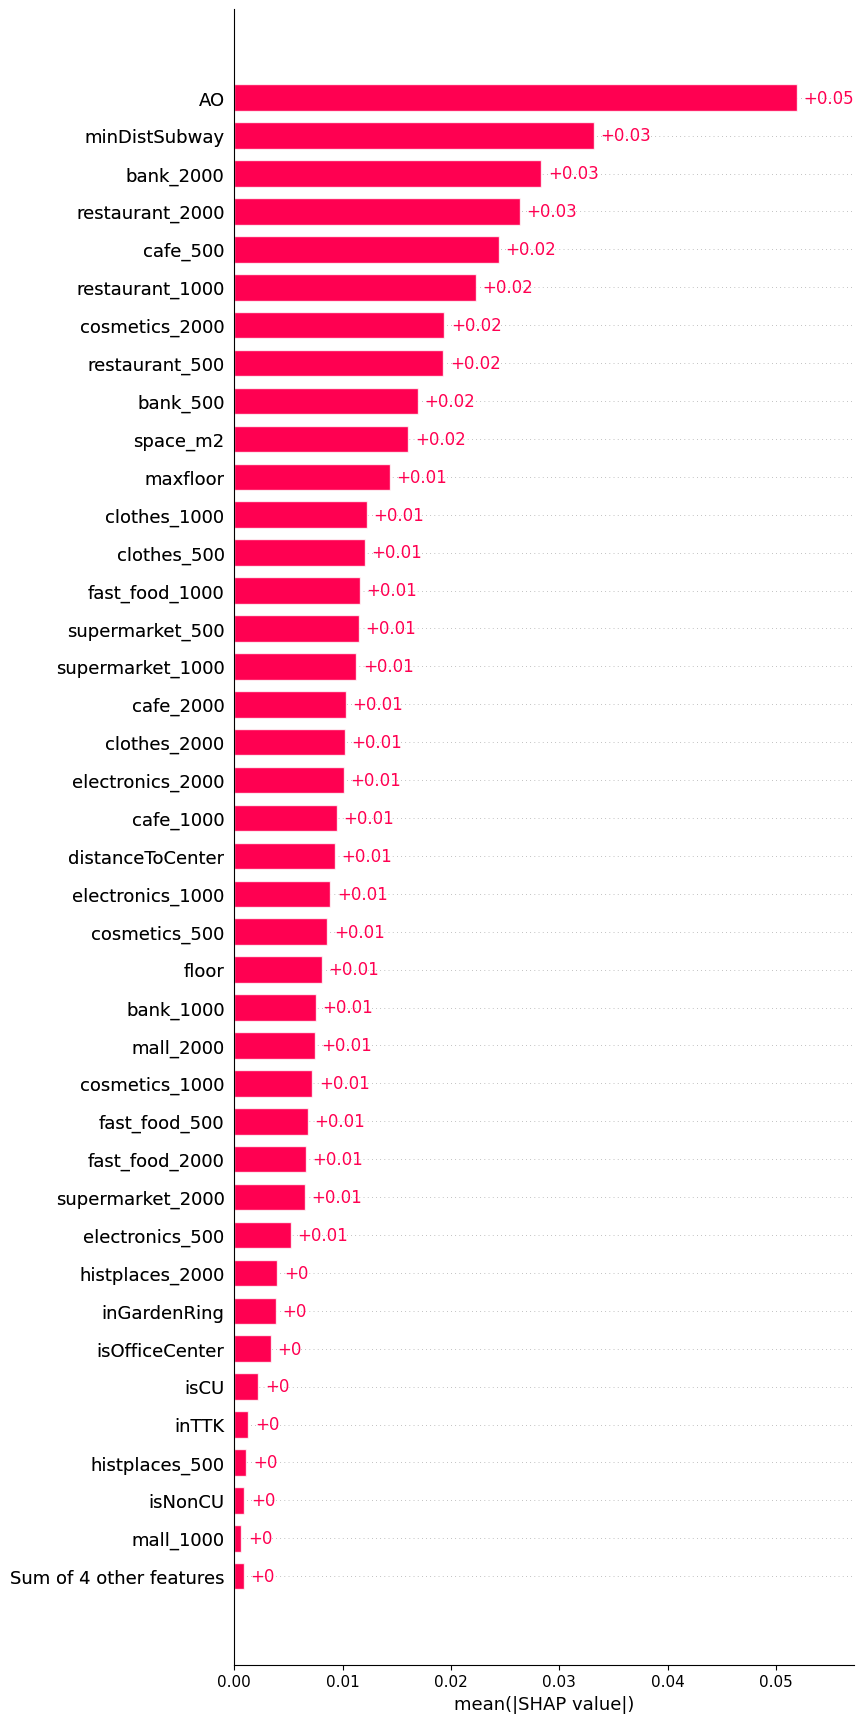

In [18]:
# Строим соответствующие графики
shap.plots.bar(shap_values, max_display=40)